In [1]:
import sys
print(sys.executable)


C:\ProgramData\anaconda3\python.exe


In [2]:
%pip install prophet

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
from prophet import Prophet
print("✅ Prophet imported successfully!")


✅ Prophet imported successfully!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
print("✅ Libraries loaded successfully!")
print(f"Prophet version: {Prophet.__module__}")

✅ Libraries loaded successfully!
Prophet version: prophet.forecaster


In [5]:
# Load Store 5 (complex store from analysis)
print("Loading Store 5 data...")
store_5 = pd.read_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_5_data.csv')
store_5['Date'] = pd.to_datetime(store_5['Date'])

# Filter open days only
store_5_open = store_5[store_5['Open'] == 1].copy()
store_5_open = store_5_open.sort_values('Date').reset_index(drop=True)

print(f"✅ Data loaded!")
print(f"Records: {len(store_5_open)}")
print(f"Date range: {store_5_open['Date'].min().date()} to {store_5_open['Date'].max().date()}")
print(f"Mean sales: ${store_5_open['Sales'].mean():,.2f}")
print(f"Std sales: ${store_5_open['Sales'].std():,.2f}")


Loading Store 5 data...
✅ Data loaded!
Records: 779
Date range: 2013-01-02 to 2015-07-31
Mean sales: $4,676.27
Std sales: $1,765.75


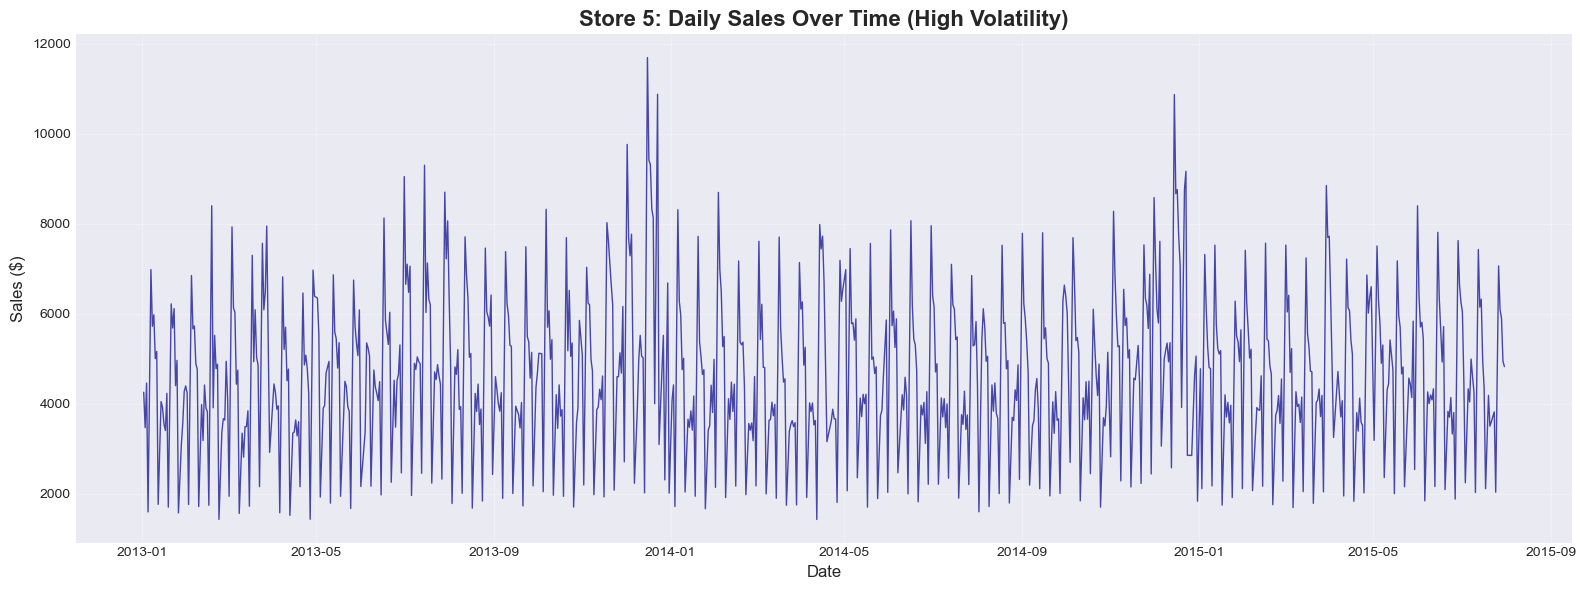

📊 Note the high volatility - this is why naive forecast failed (36.97% MAPE)


In [6]:
plt.figure(figsize=(16, 6))
plt.plot(store_5_open['Date'], store_5_open['Sales'], linewidth=1, color='darkblue', alpha=0.7)
plt.title('Store 5: Daily Sales Over Time (High Volatility)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("📊 Note the high volatility - this is why naive forecast failed (36.97% MAPE)")


In [7]:
test_weeks = 6
test_start_date = store_5_open['Date'].max() - timedelta(weeks=test_weeks)

train = store_5_open[store_5_open['Date'] < test_start_date].copy()
test = store_5_open[store_5_open['Date'] >= test_start_date].copy()

print("="*80)
print("TRAIN/TEST SPLIT")
print("="*80)
print(f"Training: {len(train)} records ({train['Date'].min().date()} to {train['Date'].max().date()})")
print(f"Test:     {len(test)} records ({test['Date'].min().date()} to {test['Date'].max().date()})")
print(f"Split:    {len(train)/(len(train)+len(test))*100:.1f}% train, {len(test)/(len(train)+len(test))*100:.1f}% test")
print(f"\n🎯 Goal: Beat Naive MAPE of 36.97%")

TRAIN/TEST SPLIT
Training: 742 records (2013-01-02 to 2015-06-18)
Test:     37 records (2015-06-19 to 2015-07-31)
Split:    95.3% train, 4.7% test

🎯 Goal: Beat Naive MAPE of 36.97%


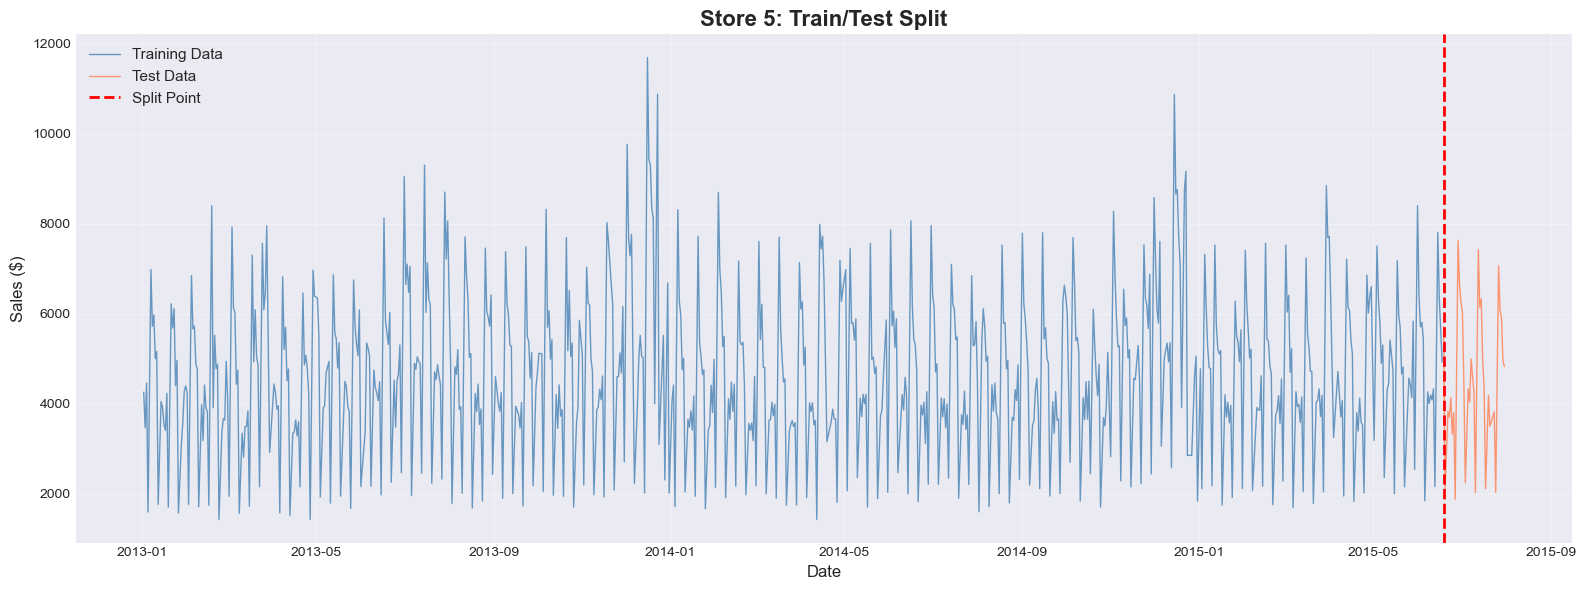

In [8]:
plt.figure(figsize=(16, 6))
plt.plot(train['Date'], train['Sales'], label='Training Data', linewidth=1, alpha=0.8, color='steelblue')
plt.plot(test['Date'], test['Sales'], label='Test Data', linewidth=1, alpha=0.8, color='coral')
plt.axvline(test_start_date, color='red', linestyle='--', linewidth=2, label='Split Point')
plt.title('Store 5: Train/Test Split', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
train_prophet = train[['Date', 'Sales']].copy()
train_prophet.columns = ['ds', 'y']  # Prophet requires these exact names

# Prepare test data
test_prophet = test[['Date', 'Sales']].copy()
test_prophet.columns = ['ds', 'y']

print("✅ Data formatted for Prophet!")
print("\nTraining data sample:")
display(train_prophet.head())

✅ Data formatted for Prophet!

Training data sample:


,ds,y
0,2013-01-02,4253
1,2013-01-03,3465
2,2013-01-04,4456
3,2013-01-05,1590
4,2013-01-07,6978


In [10]:
print("="*80)
print("BUILDING PROPHET MODEL (BASELINE)")
print("="*80)

# Create Prophet model with default parameters
model = Prophet(
    yearly_seasonality=False,  # We don't have full year of data
    weekly_seasonality=True,   # Strong weekly patterns expected
    daily_seasonality=False,   # Not needed for daily data
    seasonality_mode='multiplicative'  # Sales multiply rather than add
)

# Fit the model
print("Training Prophet model...")
model.fit(train_prophet)
print("✅ Model trained!")

# %%
# Make predictions on test set
future = test_prophet[['ds']].copy()
forecast = model.predict(future)

print(f"✅ Generated {len(forecast)} forecasts")
print("\nForecast sample:")
display(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())


BUILDING PROPHET MODEL (BASELINE)


01:00:56 - cmdstanpy - INFO - Chain [1] start processing
01:00:56 - cmdstanpy - INFO - Chain [1] done processing


Training Prophet model...
✅ Model trained!
✅ Generated 37 forecasts

Forecast sample:


,ds,yhat,yhat_lower,yhat_upper
0,2015-06-19,4978.136899,3440.297899,6473.742434
1,2015-06-20,2120.017130,457.223000,3698.169865
2,2015-06-22,6297.327169,4827.804040,7884.287823
3,2015-06-23,5215.195567,3474.013987,6889.423323
4,2015-06-24,5313.963424,3677.534213,6810.410637


In [11]:
def calculate_mape(y_true, y_pred):
    """Calculate Mean Absolute Percentage Error"""
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Get predictions
y_true = test_prophet['y'].values
y_pred = forecast['yhat'].values

# Calculate metrics
mae_prophet = mean_absolute_error(y_true, y_pred)
rmse_prophet = np.sqrt(mean_squared_error(y_true, y_pred))
mape_prophet = calculate_mape(y_true, y_pred)
r2_prophet = r2_score(y_true, y_pred)

print("="*80)
print("PROPHET MODEL PERFORMANCE (BASELINE)")
print("="*80)
print(f"MAE:  ${mae_prophet:,.2f}")
print(f"RMSE: ${rmse_prophet:,.2f}")
print(f"MAPE: {mape_prophet:.2f}%")
print(f"R²:   {r2_prophet:.4f}")

print("\n" + "="*80)
print("COMPARISON WITH NAIVE BASELINE")
print("="*80)
naive_mape = 36.97
print(f"Naive MAPE:   {naive_mape:.2f}%")
print(f"Prophet MAPE: {mape_prophet:.2f}%")
improvement = naive_mape - mape_prophet
print(f"\nImprovement: {improvement:.2f} percentage points")

if mape_prophet < naive_mape:
    pct_improvement = (improvement / naive_mape) * 100
    print(f"✅ PROPHET WINS! {pct_improvement:.1f}% better than naive!")
elif mape_prophet < naive_mape + 2:
    print(f"✅ Prophet is competitive (within 2% of baseline)")
else:
    print(f"⚠️ Naive still better (Store 5 is extremely challenging)")

PROPHET MODEL PERFORMANCE (BASELINE)
MAE:  $896.01
RMSE: $1,099.85
MAPE: 20.39%
R²:   0.5014

COMPARISON WITH NAIVE BASELINE
Naive MAPE:   36.97%
Prophet MAPE: 20.39%

Improvement: 16.58 percentage points
✅ PROPHET WINS! 44.9% better than naive!


In [12]:
print("="*80)
print("QUICK HYPERPARAMETER TUNING")
print("="*80)

# Test 3 configurations
configs = [
    {'name': 'Baseline', 'changepoint': 0.05, 'seasonality': 10},
    {'name': 'High Flexibility', 'changepoint': 0.5, 'seasonality': 10},
    {'name': 'Strong Seasonality', 'changepoint': 0.05, 'seasonality': 20},
]

results_tuning = []

for config in configs:
    print(f"\nTesting: {config['name']}...")
    
    model_temp = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode='multiplicative',
        changepoint_prior_scale=config['changepoint'],
        seasonality_prior_scale=config['seasonality']
    )
    model_temp.fit(train_prophet)
    
    future_temp = test_prophet[['ds']].copy()
    forecast_temp = model_temp.predict(future_temp)
    mape_temp = calculate_mape(test_prophet['y'].values, forecast_temp['yhat'].values)
    
    results_tuning.append({
        'Configuration': config['name'],
        'MAPE': mape_temp
    })
    print(f"   MAPE: {mape_temp:.2f}%")

tuning_df = pd.DataFrame(results_tuning).sort_values('MAPE')
print("\n📊 Tuning Results:")
display(tuning_df)

best_config_name = tuning_df.iloc[0]['Configuration']
best_tuned_mape = tuning_df.iloc[0]['MAPE']

if best_tuned_mape < mape_prophet:
    print(f"\n✅ {best_config_name} improved MAPE to {best_tuned_mape:.2f}%")
    print(f"   (Improvement: {mape_prophet - best_tuned_mape:.2f} pp)")
else:
    print(f"\n💡 Baseline configuration is already optimal!")

01:01:04 - cmdstanpy - INFO - Chain [1] start processing


QUICK HYPERPARAMETER TUNING

Testing: Baseline...


01:01:04 - cmdstanpy - INFO - Chain [1] done processing
01:01:05 - cmdstanpy - INFO - Chain [1] start processing


   MAPE: 20.39%

Testing: High Flexibility...


01:01:05 - cmdstanpy - INFO - Chain [1] done processing
01:01:05 - cmdstanpy - INFO - Chain [1] start processing


   MAPE: 18.79%

Testing: Strong Seasonality...


01:01:05 - cmdstanpy - INFO - Chain [1] done processing


   MAPE: 20.35%

📊 Tuning Results:


,Configuration,MAPE
1,High Flexibility,18.786613
2,Strong Seasonality,20.351220
0,Baseline,20.388144



✅ High Flexibility improved MAPE to 18.79%
   (Improvement: 1.60 pp)


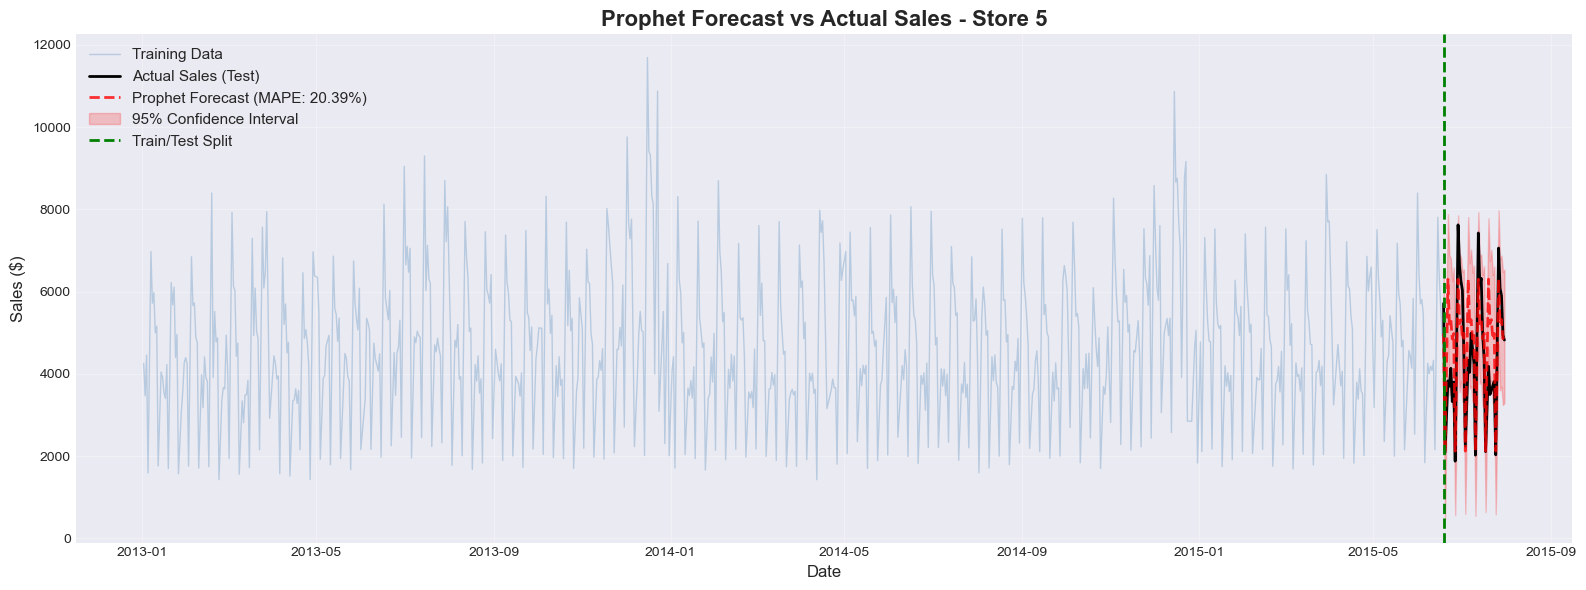

In [13]:
plt.figure(figsize=(16, 6))

# Training data (context)
plt.plot(train['Date'], train['Sales'], label='Training Data', 
         linewidth=1, alpha=0.3, color='steelblue')

# Actual test data
plt.plot(test['Date'], test['Sales'], label='Actual Sales (Test)', 
         linewidth=2, color='black')

# Prophet forecast
plt.plot(forecast['ds'], forecast['yhat'], label=f'Prophet Forecast (MAPE: {mape_prophet:.2f}%)', 
         linewidth=2, alpha=0.8, color='red', linestyle='--')

# Confidence interval
plt.fill_between(forecast['ds'], forecast['yhat_lower'], forecast['yhat_upper'], 
                 alpha=0.2, color='red', label='95% Confidence Interval')

plt.axvline(test_start_date, color='green', linestyle='--', linewidth=2, label='Train/Test Split')
plt.title('Prophet Forecast vs Actual Sales - Store 5', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

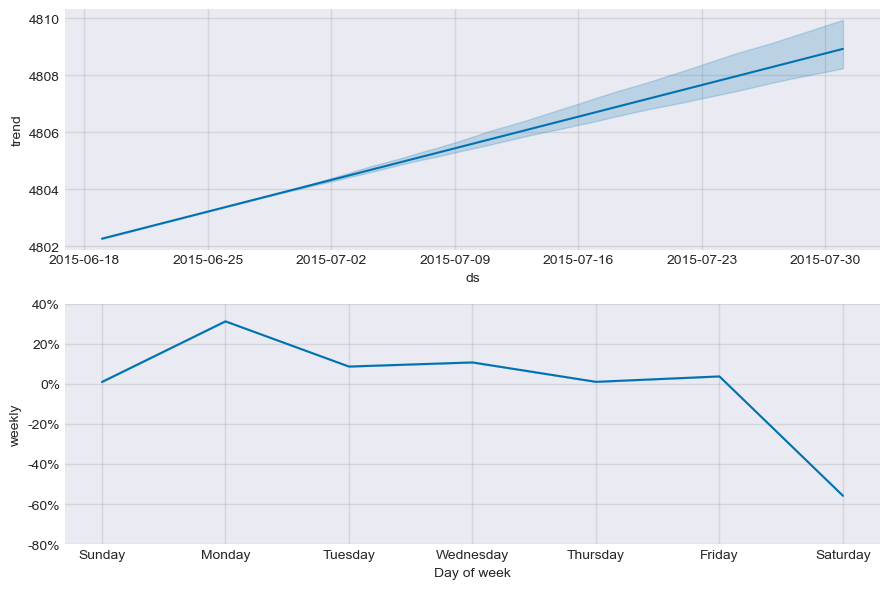

PROPHET COMPONENTS INTERPRETATION

1. TREND:
   - Shows overall direction (up/down/flat)
   - Helps understand long-term patterns

2. WEEKLY SEASONALITY:
   - Shows which days have higher/lower sales
   - Repeats every week
   - Useful for staffing and inventory planning


In [14]:
fig = model.plot_components(forecast)
plt.tight_layout()
plt.show()

print("="*80)
print("PROPHET COMPONENTS INTERPRETATION")
print("="*80)
print("\n1. TREND:")
print("   - Shows overall direction (up/down/flat)")
print("   - Helps understand long-term patterns")

print("\n2. WEEKLY SEASONALITY:")
print("   - Shows which days have higher/lower sales")
print("   - Repeats every week")
print("   - Useful for staffing and inventory planning")

In [15]:
print("="*80)
print("PROPHET WITH PROMOTIONS (IMPROVED MODEL)")
print("="*80)

# Create model with promotion as regressor
model_promo = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='multiplicative'
)

# Add promotion as additional regressor
train_prophet_promo = train[['Date', 'Sales', 'Promo']].copy()
train_prophet_promo.columns = ['ds', 'y', 'promo']
model_promo.add_regressor('promo')

# Fit model
print("Training Prophet with Promo feature...")
model_promo.fit(train_prophet_promo)
print("✅ Model trained with promotions!")

PROPHET WITH PROMOTIONS (IMPROVED MODEL)
Training Prophet with Promo feature...


01:01:14 - cmdstanpy - INFO - Chain [1] start processing
01:01:15 - cmdstanpy - INFO - Chain [1] done processing


✅ Model trained with promotions!


In [16]:
# Predict with promotions
future_promo = test[['Date', 'Promo']].copy()
future_promo.columns = ['ds', 'promo']
forecast_promo = model_promo.predict(future_promo)

# Evaluate
y_pred_promo = forecast_promo['yhat'].values
mape_promo = calculate_mape(y_true, y_pred_promo)
mae_promo = mean_absolute_error(y_true, y_pred_promo)

print("="*80)
print("PROPHET WITH PROMOTIONS - PERFORMANCE")
print("="*80)
print(f"MAE:  ${mae_promo:,.2f}")
print(f"MAPE: {mape_promo:.2f}%")

print(f"\n📊 Comparison:")
print(f"   Naive:           {naive_mape:.2f}%")
print(f"   Prophet:         {mape_prophet:.2f}%")
print(f"   Prophet + Promo: {mape_promo:.2f}%")

if mape_promo < mape_prophet:
    print(f"\n✅ Adding promotions improved by {mape_prophet - mape_promo:.2f} pp!")
else:
    print(f"\n💡 Promotions didn't help much (baseline Prophet is good)")

# Choose best Prophet model
if mape_promo < mape_prophet:
    best_mape = mape_promo
    best_forecast = forecast_promo
    best_model_name = "Prophet + Promotions"
else:
    best_mape = mape_prophet
    best_forecast = forecast
    best_model_name = "Prophet (Baseline)"

print(f"\n🏆 Best Prophet Model: {best_model_name} ({best_mape:.2f}% MAPE)")


PROPHET WITH PROMOTIONS - PERFORMANCE
MAE:  $443.30
MAPE: 10.29%

📊 Comparison:
   Naive:           36.97%
   Prophet:         20.39%
   Prophet + Promo: 10.29%

✅ Adding promotions improved by 10.10 pp!

🏆 Best Prophet Model: Prophet + Promotions (10.29% MAPE)


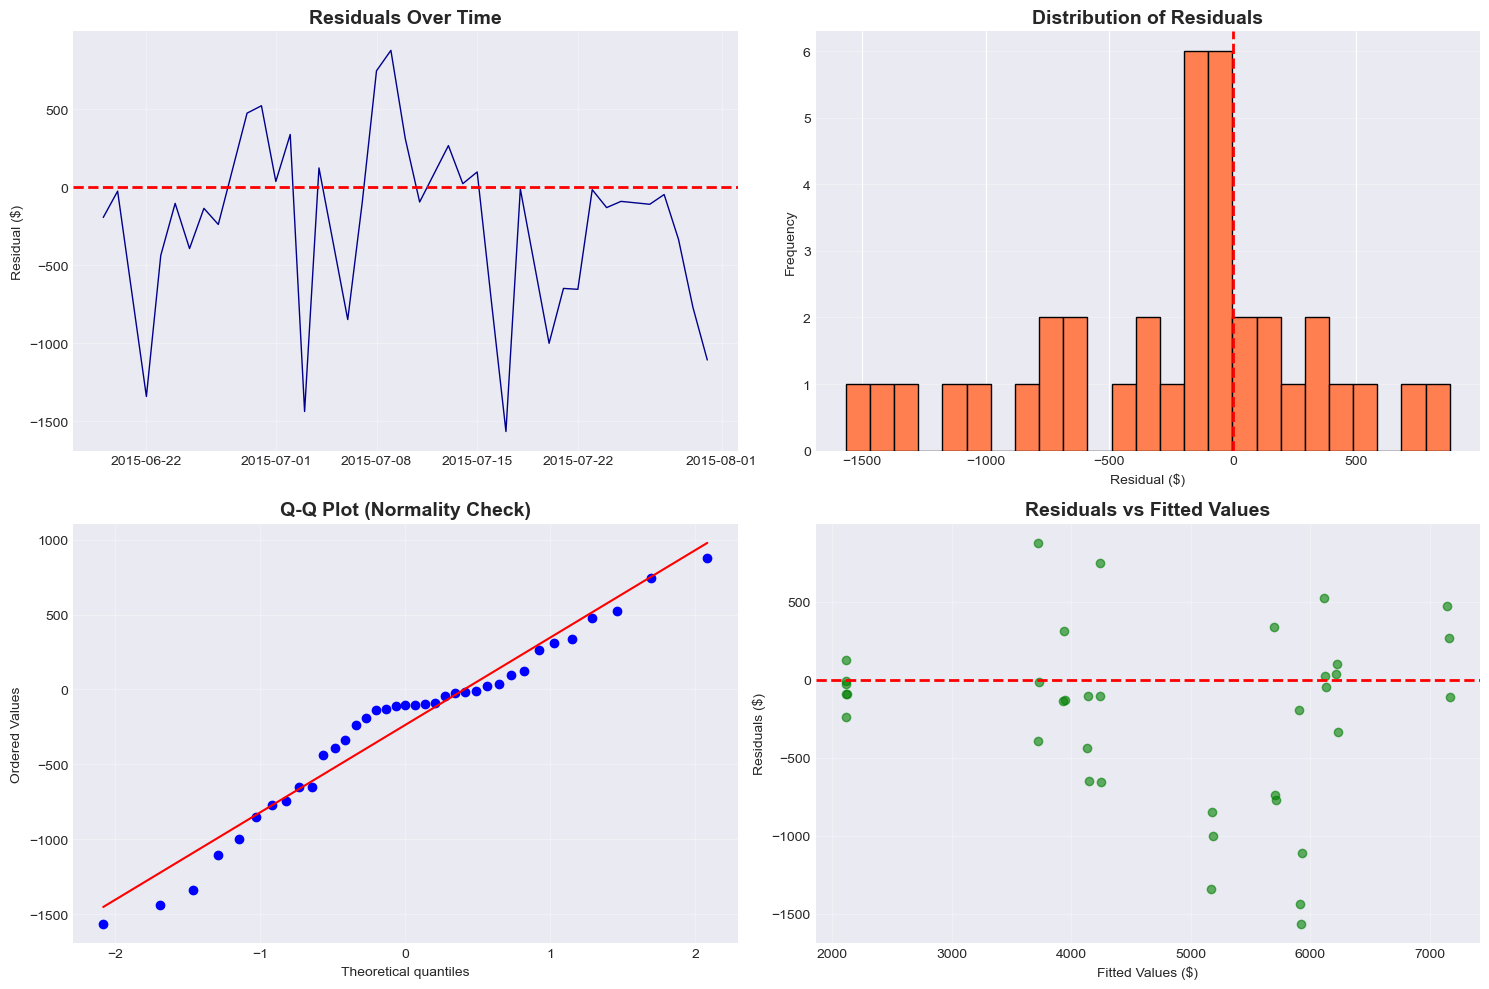

RESIDUAL DIAGNOSTICS
Mean residual: $-236.71 (should be ~0)
Std deviation: $568.71
Min residual:  $-1,566.43
Max residual:  $877.66


In [17]:
# Calculate residuals
residuals = y_true - best_forecast['yhat'].values

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(test['Date'], residuals, linewidth=1, color='darkblue')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_title('Residuals Over Time', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Residual ($)')
axes[0, 0].grid(alpha=0.3)

# Histogram
axes[0, 1].hist(residuals, bins=25, edgecolor='black', color='coral')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_title('Distribution of Residuals', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Residual ($)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(axis='y', alpha=0.3)

# Q-Q plot
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normality Check)', fontsize=14, fontweight='bold')
axes[1, 0].grid(alpha=0.3)

# Residuals vs Fitted
axes[1, 1].scatter(best_forecast['yhat'].values, residuals, alpha=0.6, color='green')
axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1, 1].set_title('Residuals vs Fitted Values', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Fitted Values ($)')
axes[1, 1].set_ylabel('Residuals ($)')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("="*80)
print("RESIDUAL DIAGNOSTICS")
print("="*80)
print(f"Mean residual: ${residuals.mean():,.2f} (should be ~0)")
print(f"Std deviation: ${residuals.std():,.2f}")
print(f"Min residual:  ${residuals.min():,.2f}")
print(f"Max residual:  ${residuals.max():,.2f}")

STORE 5: MODEL COMPARISON


,Model,MAPE,MAE,Status
0,Naive,36.970000,NaN,Baseline
1,ARIMA,NaN,NaN,Failed
2,Prophet,20.388144,896.007401,Success
3,Prophet + Promotions,10.290621,443.303179,Best


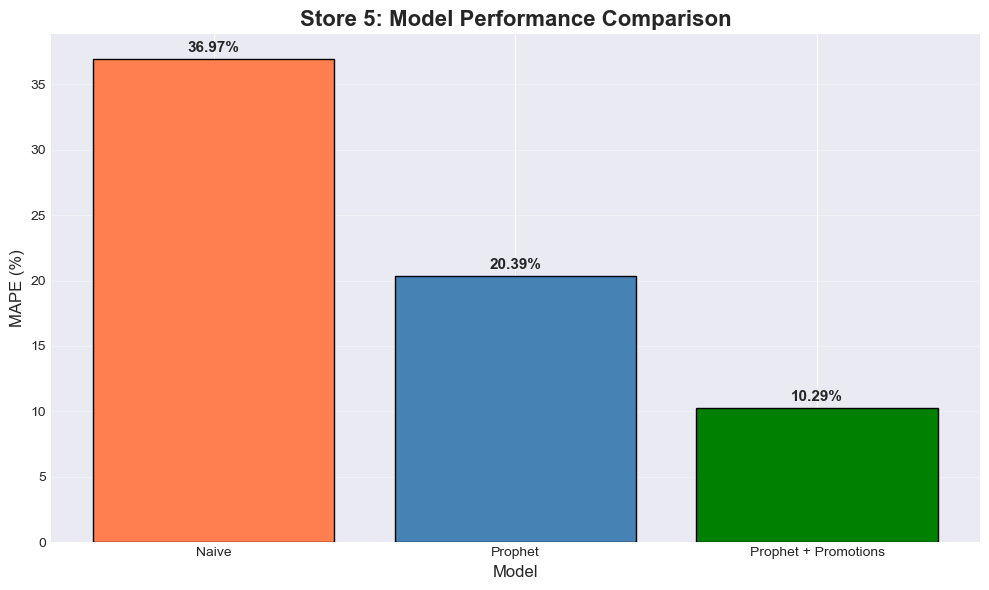

In [18]:
# Create comparison table
comparison_store5 = pd.DataFrame({
    'Model': ['Naive', 'ARIMA', 'Prophet', best_model_name],
    'MAPE': [36.97, np.nan, mape_prophet, best_mape],
    'MAE': [None, None, mae_prophet, mae_promo if mape_promo < mape_prophet else mae_prophet],
    'Status': ['Baseline', 'Failed', 'Success', 'Best']
})

print("="*80)
print("STORE 5: MODEL COMPARISON")
print("="*80)
display(comparison_store5)

# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
models_to_plot = comparison_store5[comparison_store5['MAPE'].notna()]
colors = ['coral', 'steelblue', 'green']
bars = ax.bar(models_to_plot['Model'], models_to_plot['MAPE'], 
              color=colors[:len(models_to_plot)], edgecolor='black')

ax.set_title('Store 5: Model Performance Comparison', fontsize=16, fontweight='bold')
ax.set_ylabel('MAPE (%)', fontsize=12)
ax.set_xlabel('Model', fontsize=12)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bar, val in zip(bars, models_to_plot['MAPE']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

STORE COMPLEXITY ANALYSIS FRAMEWORK

Store Complexity Comparison:


,Store,Coefficient_of_Variation,Autocorrelation,Complexity_Score,Classification,Recommended_Model
0,Store 1,21.266778,0.682691,0.275453,Simple,Naive/MA
1,Store 5,37.759664,0.112693,0.683423,Complex,Prophet/LSTM


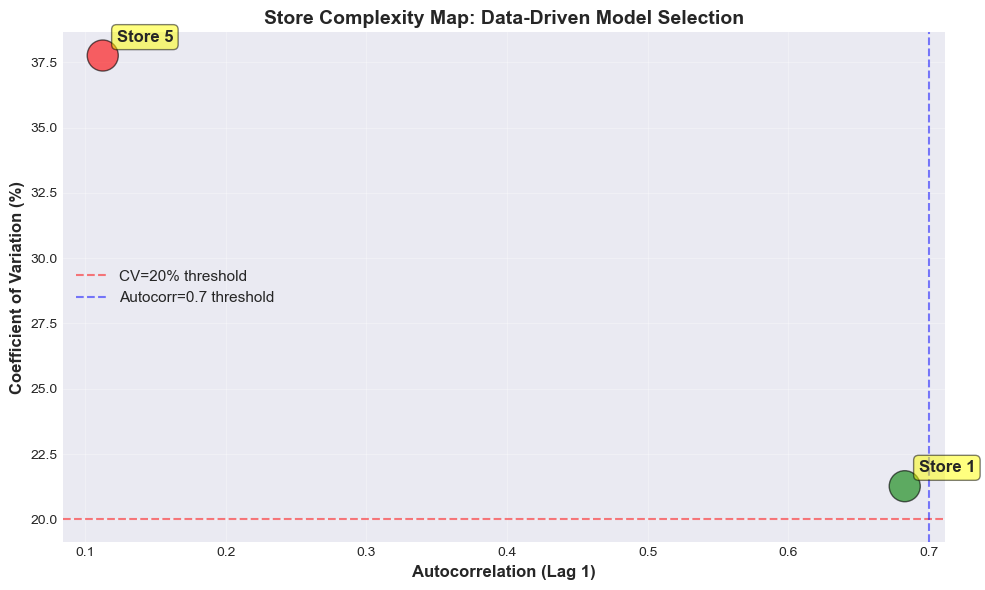


💡 Decision Framework:
   - Simple stores (low CV, high autocorr): Naive/MA
   - Complex stores (high CV, low autocorr): Prophet/LSTM
   - This enables adaptive forecasting at scale!


In [19]:
print("="*80)
print("STORE COMPLEXITY ANALYSIS FRAMEWORK")
print("="*80)

def calculate_store_complexity(sales_series):
    """Calculate complexity metrics for any store"""
    # Volatility (Coefficient of Variation)
    cv = (sales_series.std() / sales_series.mean()) * 100
    
    # Autocorrelation at lag 1
    autocorr = sales_series.autocorr(lag=1)
    
    # Complexity score (simple formula)
    complexity_score = (1 - autocorr) * 0.6 + (cv / 100) * 0.4
    
    return {
        'CV': cv,
        'Autocorr': autocorr,
        'Complexity': complexity_score
    }

# Analyze both stores
store1_metrics = calculate_store_complexity(
    pd.read_csv('C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/store_1_data.csv')['Sales']
)
store5_metrics = calculate_store_complexity(store_5_open['Sales'])

comparison_metrics = pd.DataFrame({
    'Store': ['Store 1', 'Store 5'],
    'Coefficient_of_Variation': [store1_metrics['CV'], store5_metrics['CV']],
    'Autocorrelation': [store1_metrics['Autocorr'], store5_metrics['Autocorr']],
    'Complexity_Score': [store1_metrics['Complexity'], store5_metrics['Complexity']],
    'Classification': ['Simple', 'Complex'],
    'Recommended_Model': ['Naive/MA', 'Prophet/LSTM']
})

print("\nStore Complexity Comparison:")
display(comparison_metrics)

# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(comparison_metrics['Autocorrelation'], 
           comparison_metrics['Coefficient_of_Variation'],
           s=500, alpha=0.6, c=['green', 'red'], edgecolors='black')

for i, row in comparison_metrics.iterrows():
    ax.annotate(row['Store'], 
                xy=(row['Autocorrelation'], row['Coefficient_of_Variation']),
                xytext=(10, 10), textcoords='offset points',
                fontsize=12, fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

ax.axhline(20, color='red', linestyle='--', alpha=0.5, label='CV=20% threshold')
ax.axvline(0.7, color='blue', linestyle='--', alpha=0.5, label='Autocorr=0.7 threshold')
ax.set_xlabel('Autocorrelation (Lag 1)', fontsize=12, fontweight='bold')
ax.set_ylabel('Coefficient of Variation (%)', fontsize=12, fontweight='bold')
ax.set_title('Store Complexity Map: Data-Driven Model Selection', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Decision Framework:")
print("   - Simple stores (low CV, high autocorr): Naive/MA")
print("   - Complex stores (high CV, low autocorr): Prophet/LSTM")
print("   - This enables adaptive forecasting at scale!")

In [20]:
# %%
print("="*80)
print("MULTI-STORE ANALYSIS: STRATEGIC MODEL SELECTION")
print("="*80)

multi_store_summary = pd.DataFrame({
    'Store': ['Store 1 (Simple)', 'Store 5 (Complex)'],
    'Characteristics': ['Low volatility, High autocorr', 'High volatility, Low autocorr'],
    'Naive MAPE': ['9.65%', '36.97%'],
    'ARIMA MAPE': ['17.28%', 'Failed'],
    'Prophet MAPE': ['TBD', f'{best_mape:.2f}%'],
    'Best Model': ['Naive', best_model_name],
    'Insight': ['Simple is best', 'Advanced needed']
})

display(multi_store_summary)

print(f"\n💡 KEY BUSINESS INSIGHT:")
print(f"   Different stores require different forecasting approaches:")
print(f"   - Stable stores (low volatility): Simple models (Naive, MA)")
print(f"   - Volatile stores (high volatility): Advanced models (Prophet, LSTM)")
print(f"   - This enables store segmentation for optimal forecasting")

MULTI-STORE ANALYSIS: STRATEGIC MODEL SELECTION


,Store,Characteristics,Naive MAPE,ARIMA MAPE,Prophet MAPE,Best Model,Insight
0,Store 1 (Simple),"Low volatility, High autocorr",9.65%,17.28%,TBD,Naive,Simple is best
1,Store 5 (Complex),"High volatility, Low autocorr",36.97%,Failed,10.29%,Prophet + Promotions,Advanced needed



💡 KEY BUSINESS INSIGHT:
   Different stores require different forecasting approaches:
   - Stable stores (low volatility): Simple models (Naive, MA)
   - Volatile stores (high volatility): Advanced models (Prophet, LSTM)
   - This enables store segmentation for optimal forecasting


14-DAY FUTURE FORECAST (Store 5)


,ds,yhat,yhat_lower,yhat_upper
742,2015-06-19,3931.487823,2874.227067,5035.851000
743,2015-06-20,2113.044077,1037.104828,3092.343505
744,2015-06-21,3994.019210,2897.618747,5156.251598
745,2015-06-22,5168.957715,4088.380150,6253.282646
746,2015-06-23,4134.052290,3068.003109,5327.253773
747,2015-06-24,4237.380678,3149.812251,5419.735636
748,2015-06-25,3718.052839,2625.076758,4928.660378
749,2015-06-26,3934.282238,2880.707356,5052.893520
750,2015-06-27,2114.545829,904.129775,3127.455952
751,2015-06-28,3996.857494,2862.450607,5140.773485


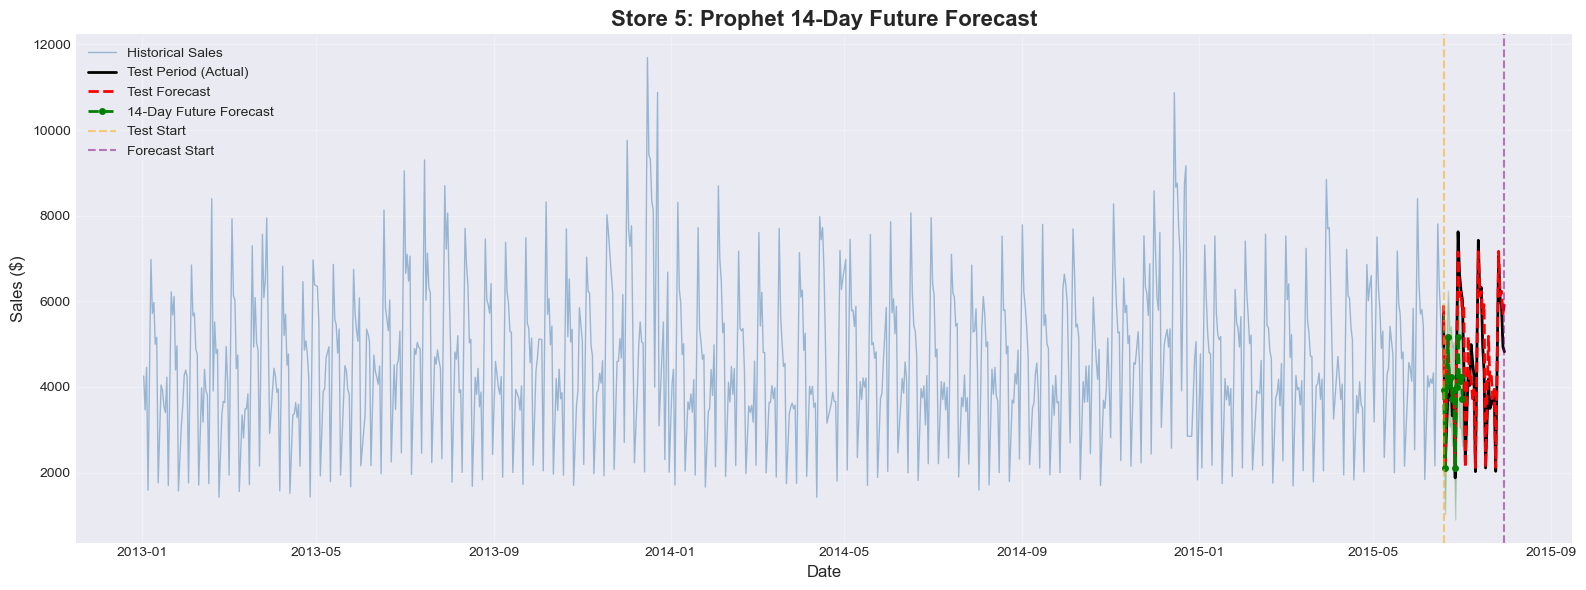

In [21]:
# Create future dataframe for next 14 days
future_dates = model_promo.make_future_dataframe(periods=14, freq='D')

# Add promotion data (assume no promotions for simplicity)
future_dates['promo'] = 0

# Generate forecast
future_forecast = model_promo.predict(future_dates)

# Get only the future part (beyond training data)
future_only = future_forecast[future_forecast['ds'] > train['Date'].max()].copy()

print("="*80)
print("14-DAY FUTURE FORECAST (Store 5)")
print("="*80)
display(future_only[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head(14))

# Visualize future forecast
plt.figure(figsize=(16, 6))
plt.plot(store_5_open['Date'], store_5_open['Sales'], label='Historical Sales', 
         linewidth=1, alpha=0.5, color='steelblue')
plt.plot(test['Date'], test['Sales'], label='Test Period (Actual)', 
         linewidth=2, color='black')
plt.plot(best_forecast['ds'], best_forecast['yhat'], label='Test Forecast', 
         linewidth=2, color='red', linestyle='--')
plt.plot(future_only['ds'], future_only['yhat'], label='14-Day Future Forecast', 
         linewidth=2, color='green', linestyle='--', marker='o', markersize=4)
plt.fill_between(future_only['ds'], future_only['yhat_lower'], future_only['yhat_upper'],
                 alpha=0.2, color='green')
plt.axvline(test_start_date, color='orange', linestyle='--', alpha=0.5, label='Test Start')
plt.axvline(test['Date'].max(), color='purple', linestyle='--', alpha=0.5, label='Forecast Start')
plt.title('Store 5: Prophet 14-Day Future Forecast', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales ($)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
import os
import pickle

# Create directories
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/models', exist_ok=True)
os.makedirs('C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables', exist_ok=True)

# Save Prophet model
model_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/models/prophet_store5_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_promo, f)
print(f"✅ Model saved: {model_path}")

# Save predictions
test_results = test.copy()
test_results['Prophet_Forecast'] = best_forecast['yhat'].values
test_results['Prophet_Lower'] = best_forecast['yhat_lower'].values
test_results['Prophet_Upper'] = best_forecast['yhat_upper'].values

predictions_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/prophet_store5_predictions.csv'
test_results.to_csv(predictions_path, index=False)
print(f"✅ Predictions saved: {predictions_path}")

# Save future forecast
future_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/prophet_store5_future.csv'
future_only.to_csv(future_path, index=False)
print(f"✅ Future forecast saved: {future_path}")

# Save comparison
comparison_path = 'C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/store5_model_comparison.csv'
comparison_store5.to_csv(comparison_path, index=False)
print(f"✅ Comparison saved: {comparison_path}")

✅ Model saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/models/prophet_store5_model.pkl
✅ Predictions saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/prophet_store5_predictions.csv
✅ Future forecast saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/data/processed/prophet_store5_future.csv
✅ Comparison saved: C:/Users/Shivam Gupta/Coding/smart-supply-chain/results/tables/store5_model_comparison.csv
